 ================================================================================================================================================================================================

 NOTEBOOK 04 — ZHU GUARDED LWC RETRIEVAL (CLEANED)

 ================================================================================================================================================================================================



 Pipeline: load data -> 30 s time-average DWR -> dDWR/dH diagnostic ->

 Zhu **guarded** retrieval -> LWC quality checks -> LWP (3 checks only, for later comparison)



 Removed in this cleanup (all still recoverable from notebook history if needed):

   - 60 s time-averaging branch

   - Raw / un-averaged Zhu retrieval exploration (superseded by the 30 s branch, which is

     what feeds the guarded retrieval anyway)

   - Most LWP diagnostics — kept only: general LWP time series, LWP closure scatter,

     and the "spot check three profiles" comparison

   - 500-1500 m windowed retrieval experiment

   - common_mask (C1/C2) redundant second retrieval pass

 ================================================================================================================================================================================================

 ## 0. Setup

In [2]:
from pathlib import Path

retrieval_dir = Path("../src/radar_lwc/retrieval").resolve()
print(retrieval_dir)
print(list(retrieval_dir.glob("*.py")))


C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval
[WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/average_ze_time.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/ddwr_dh.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dielectric.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dq_retrieval.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/gas_attenuation.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/kappa_liquid.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/rpg_chirp_table.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/zhu.py')]


In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append(str(Path("../src").resolve()))

# Preprocessing
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity

# Retrieval
from radar_lwc.retrieval.average_ze_time import avg_ze_time
from radar_lwc.retrieval.ddwr_dh import compute_ddwr_dh
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.kappa_liquid import kappa_liquid
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu


In [4]:
Processed_Dataset = "20261002_pallas_interpolation_CLARA"

In [5]:
in_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(in_path)
print(ds_retrieval)


<xarray.Dataset> Size: 711MB
Dimensions:          (Time: 35268, range: 237)
Coordinates:
  * Time             (Time) datetime64[ns] 282kB 2026-10-02T00:46:20.57291507...
  * range            (range) float64 2kB 104.3 119.3 ... 3.952e+03 3.986e+03
Data variables: (12/16)
    Ze_W             (Time, range) float64 67MB ...
    Ze_Ka            (Time, range) float64 67MB ...
    T_cloud          (Time, range) float64 67MB ...
    LWP              (Time) float32 141kB ...
    DWR              (Time, range) float64 67MB ...
    cloud_mask       (Time, range) bool 8MB ...
    ...               ...
    alpha_W          (Time, range) float64 67MB ...
    alpha_Ka         (Time, range) float64 67MB ...
    kappa_W          (Time, range) float64 67MB ...
    kappa_Ka         (Time, range) float64 67MB ...
    MeanVel_W        (Time, range) float64 67MB ...
    MeanVel_Ka       (Time, range) float64 67MB ...
Attributes:
    description:  Prepared inputs for Zhu et al. (2019) LWC retrieval with al

In [6]:
mm = ds_retrieval["common_mask_raw"].fillna(0).astype(bool).values
multi = [p.sum() > 1 and np.diff(np.flatnonzero(p)).max() > 4 for p in mm]
print(f"profiles with a second layer (gap > 3 gates): {np.mean(multi):.1%}")

profiles with a second layer (gap > 3 gates): 3.8%


 ================================================================================================================================================================================================

 ## 1. Time averaging (30 s only)



 Averaging Ze in linear space before forming DWR beats down per-gate DWR noise, which is a

 prerequisite for a physically meaningful dDWR/dH gradient. 30 s was kept as the working

 resolution; 60 s is dropped for now (barely changed the diagnostics — restore quickly by

 copying the `window_s=60` block back in if a comparison is ever needed again).

 ================================================================================================================================================================================================

In [7]:
ze_ka_avg = avg_ze_time(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)), window_s=30)
ze_w_avg  = avg_ze_time(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)),  window_s=30)

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"


In [8]:
# %% 1 dB gate-to-gate filter (Socuellamos): replace spikes by linear interpolation
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    """
    dwr_1d: 1D array along range for a single time step.
    A gate i is an outlier if it differs from BOTH neighbours by more than
    `threshold` dB in the same direction (i.e. it's a spike relative to a
    smooth profile) -> replaced by linear interpolation between i-1 and i+1.
    """
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)   # same direction on both sides
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5  # linear interp
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d,
    dwr_2km_smoothed,
    input_core_dims=[["range"]],
    output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold},
    vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")

Gates replaced by interpolation: 21521 (0.26% of all gates)


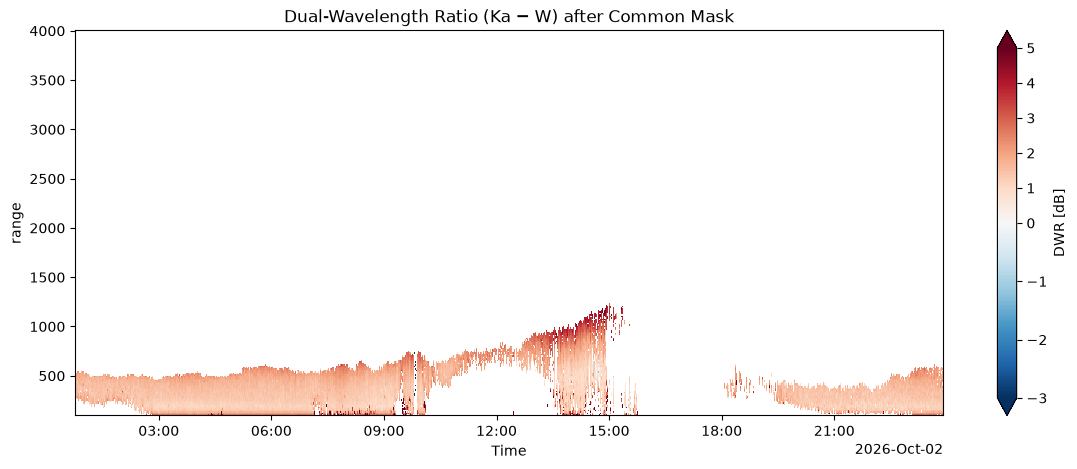

In [9]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(14, 5))

dwr_2km_filt.where(ds_retrieval["common_mask"]).plot(
    x="Time",
    y="range",
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=5),
    ax=ax,
    cbar_kwargs={"label": "DWR [dB]"}
)

ax.set_title("Dual-Wavelength Ratio (Ka − W) after Common Mask")
plt.show()

 ## 2. dDWR/dH diagnostic (30 s smoothed input)



 This is the key sanity check before trusting the gradient-based retrieval: how much of the

 in-cloud gradient is still noise (negative or unphysically large |dDWR/dH|)?

In [10]:
ddwr_dh_smoothed = compute_ddwr_dh(dwr_2km_filt, ds_retrieval["common_mask"], N_default=13)

vals = ddwr_dh_smoothed.where(ds_retrieval["common_mask"]).values.ravel()
vals = vals[np.isfinite(vals)]
print("After 30 s time-averaging:")
print(f"  Fraction dDWR/dh < 0:          {(vals < 0).mean():.2%}")
print(f"  Fraction |dDWR/dh| > 30 dB/km: {(np.abs(vals) > 30).mean():.2%}")
print(f"  median dDWR/dh:                {np.median(vals):.2f} dB/km")


After 30 s time-averaging:
  Fraction dDWR/dh < 0:          29.12%
  Fraction |dDWR/dh| > 30 dB/km: 1.10%
  median dDWR/dh:                1.99 dB/km


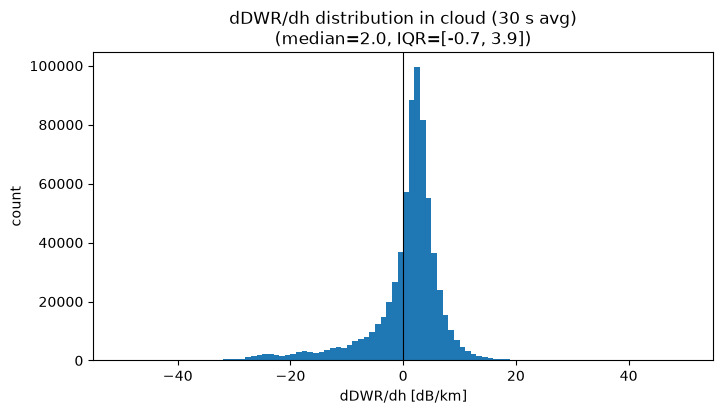

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals, bins=100, range=(-50, 50))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("dDWR/dh [dB/km]")
ax.set_ylabel("count")
ax.set_title(f"dDWR/dh distribution in cloud (30 s avg)\n"
             f"(median={np.median(vals):.1f}, "
             f"IQR=[{np.percentile(vals,25):.1f}, {np.percentile(vals,75):.1f}])")
plt.show()


 (Supporting context for the guard thresholds below — per-gate DWR noise estimate from

 vertical-neighbour differences.)

In [12]:
D = dwr_2km_filt.where(ds_retrieval["common_mask"]).values                 #Filtered DWR values where the common mask is True
diffs = D[:, 1:] - D[:, :-1]                                  # DWR(i+1)−DWR(i)   Subtracting the DWR value of the next gate from the current gate to get the difference between adjacent gates
diffs = diffs[np.isfinite(diffs)]               # Remove NaN
noise_estimate = np.std(diffs) / np.sqrt(2)      #standard deviation of the difference tells how widely these differences scatter. Signal is supposed to be the same in neighbouring gates, so difference should be zero. Rest is just noise. The Variance Difference is Var(Ni+1​−Ni​)= Var(Ni+1​)+Var(Ni​) = σ^2+σ^2 =2σ^2.Therefore: Std(Ni+1​−Ni​)=sqrt(2)*σ Finally: noise = std_difference / np.sqrt(2)
print(f"Estimated per-gate DWR noise: {noise_estimate:.2f} dB")
print(f"Median in-cloud DWR:          {float(dwr_2km_filt.where(ds_retrieval['common_mask']).median()):.2f} dB")
print(f"Signal across a 9-gate (~200 m) window at 5 dB/km: {5 * 0.20:.2f} dB")    # Comparison Noise and Signal across  Window


Estimated per-gate DWR noise: 0.28 dB
Median in-cloud DWR:          1.54 dB
Signal across a 9-gate (~200 m) window at 5 dB/km: 1.00 dB


 ================================================================================================================================================================================================

 ## 3. Zhu Guarded retrieval



 Drop-in replacement for the plain gradient retrieval: overlap-averages the window fit and

 rejects windows that are too noisy (`max_window_std`) or produce an unphysical gradient

 (`max_ddwr_dh`), with `edge_pad` gates skipped near cloud base/top.

 ================================================================================================================================================================================================

In [13]:
def retrieve_lwc_zhu_guarded(
    dwr, kappa_w, kappa_ka, alpha_w, alpha_ka, common_mask,
    N_default=9,
    max_ddwr_dh=50.0,      # dB/km — physical ceiling on |dDWR/dh|
    max_window_std=3.0,    # dB    — reject noisy windows
    edge_pad=1,            # skip edge gates near cloud base/top
):
    """
    Zhu-style LWC retrieval with overlap averaging + sanity guards.
    Assumes dims ('Time', 'range'). Returns (LWC g/m^3, n_windows per gate).
    """
    h = dwr["range"].values.astype(float)
    D = dwr.values
    Kw, Kka = kappa_w.values, kappa_ka.values
    Aw, Aka = alpha_w.values, alpha_ka.values
    M = common_mask.values
    nt, nr = D.shape

    lwc_sum = np.zeros_like(D)
    lwc_cnt = np.zeros_like(D)

    for t in range(nt):
        cloud_idx = np.flatnonzero(M[t])
        if cloud_idx.size < 3:
            continue
        i0 = cloud_idx.min() + edge_pad
        i1 = cloud_idx.max() - edge_pad
        if i1 - i0 + 1 < 3:
            continue
        Nt = min(N_default, i1 - i0 + 1)

        for i in range(i0, i1 - Nt + 2):
            sl = slice(i, i + Nt)
            if not M[t, sl].all():
                continue
            dwin = D[t, sl]
            if not np.isfinite(dwin).all():
                continue
            if dwin.std() > max_window_std:
                continue
            a, b, _c = np.polyfit(h[sl], dwin, 2)
            grad = (2 * a * h[sl] + b) * 1000.0   # dB/km
            if np.any(np.abs(grad) > max_ddwr_dh):
                continue
            dkappa = Kw[t, sl] - Kka[t, sl]
            dalpha = Aw[t, sl] - Aka[t, sl]
            with np.errstate(divide="ignore", invalid="ignore"):
                lwc_win = (0.5 * grad - dalpha) / dkappa
            lwc_sum[t, sl] += lwc_win
            lwc_cnt[t, sl] += 1

    with np.errstate(invalid="ignore", divide="ignore"):
        lwc = np.where(lwc_cnt > 0, lwc_sum / lwc_cnt, np.nan)

    lwc_da = xr.DataArray(
        lwc, coords=dwr.coords, dims=dwr.dims, name="lwc",
        attrs={"units": "g m-3", "long_name": "LWC (Zhu 2019, guarded)"},
    )
    n_da = xr.DataArray(lwc_cnt, coords=dwr.coords, dims=dwr.dims, name="n_windows")
    return lwc_da, n_da

 # DONT USE CODE ABOVE HERE RIGHT NOW ANYMORE: CHANGED MY zhu.py TO BE GUARDED RETRIEVAL, SO USE THAT INSTEAD
lwc_guarded, derivative_guarded, m_eff, n_windows, n_used= retrieve_lwc_zhu( 
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["common_mask"],
    N_default=13,
    min_cloud_gates=3,
    max_ddwr_dh=30.0,
    max_window_std=1,
    edge_pad_bottom=2,
    edge_pad_top=1
)

print(f"Gates with any retrieval: {int((n_windows > 0).sum())} "
      f"({100*float((n_windows>0).mean()):.1f}%)")
print(f"Mean windows per gate:    {float(n_windows.where(n_windows>0).mean()):.1f}")


Gates with any retrieval: 615028 (7.4%)
Mean windows per gate:    6.5


In [14]:
import inspect
print(inspect.getfile(retrieve_lwc_zhu))

C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval\zhu.py


In [15]:
print(retrieve_lwc_zhu)

<function retrieve_lwc_zhu at 0x0000020D31B93740>


 ================================================================================================================================================================================================

 ## 4. LWC quality checks (kept: LWC<0, LWC maps, dDWR/dH already above, + 2 supporting graphs)

 ================================================================================================================================================================================================

 ### 4a. LWC < 0

In [16]:
print(f"Fraction LWC < 0: "
      f"{float((lwc_guarded < 0).sum() / lwc_guarded.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc_guarded.quantile(0.05)):.2f}, "
      f"p50={float(lwc_guarded.quantile(0.5)):.2f}, "
      f"p95={float(lwc_guarded.quantile(0.95)):.2f} g/m^3")


Fraction LWC < 0: 27.35%
LWC quantiles: p05=-0.77, p50=0.19, p95=0.98 g/m^3


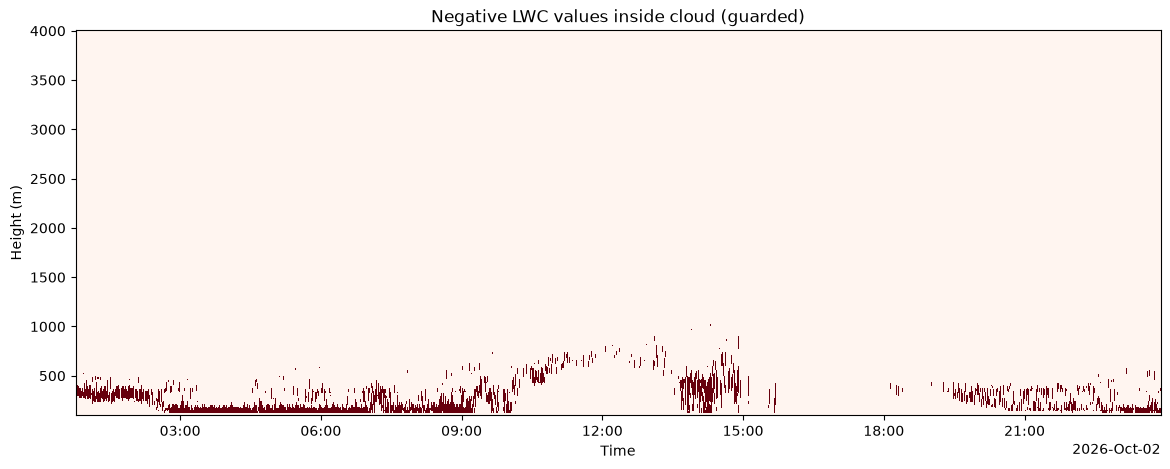

In [17]:
negative_lwc = (lwc_guarded < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_lwc.astype(int).plot(x="Time", y="range", cmap="Reds", add_colorbar=False)
plt.title("Negative LWC values inside cloud (guarded)")
plt.xlabel("Time"); plt.ylabel("Height (m)")
plt.show()


 ### 4b. LWC map (main output)

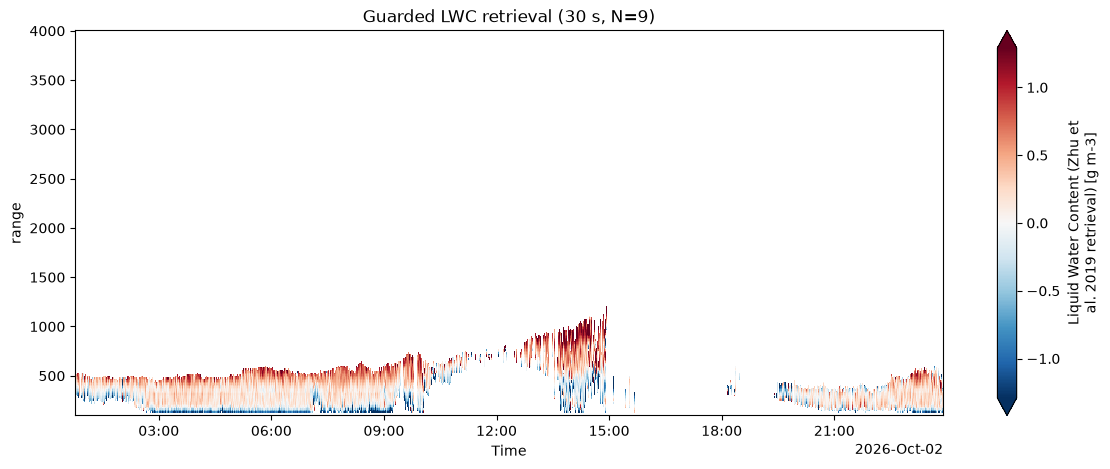

In [18]:
lwc_guarded.plot(
    x="Time", y="range", figsize=(14, 5), cmap="RdBu_r", robust=True,
)
plt.title("Guarded LWC retrieval (30 s, N=9)")
plt.show()


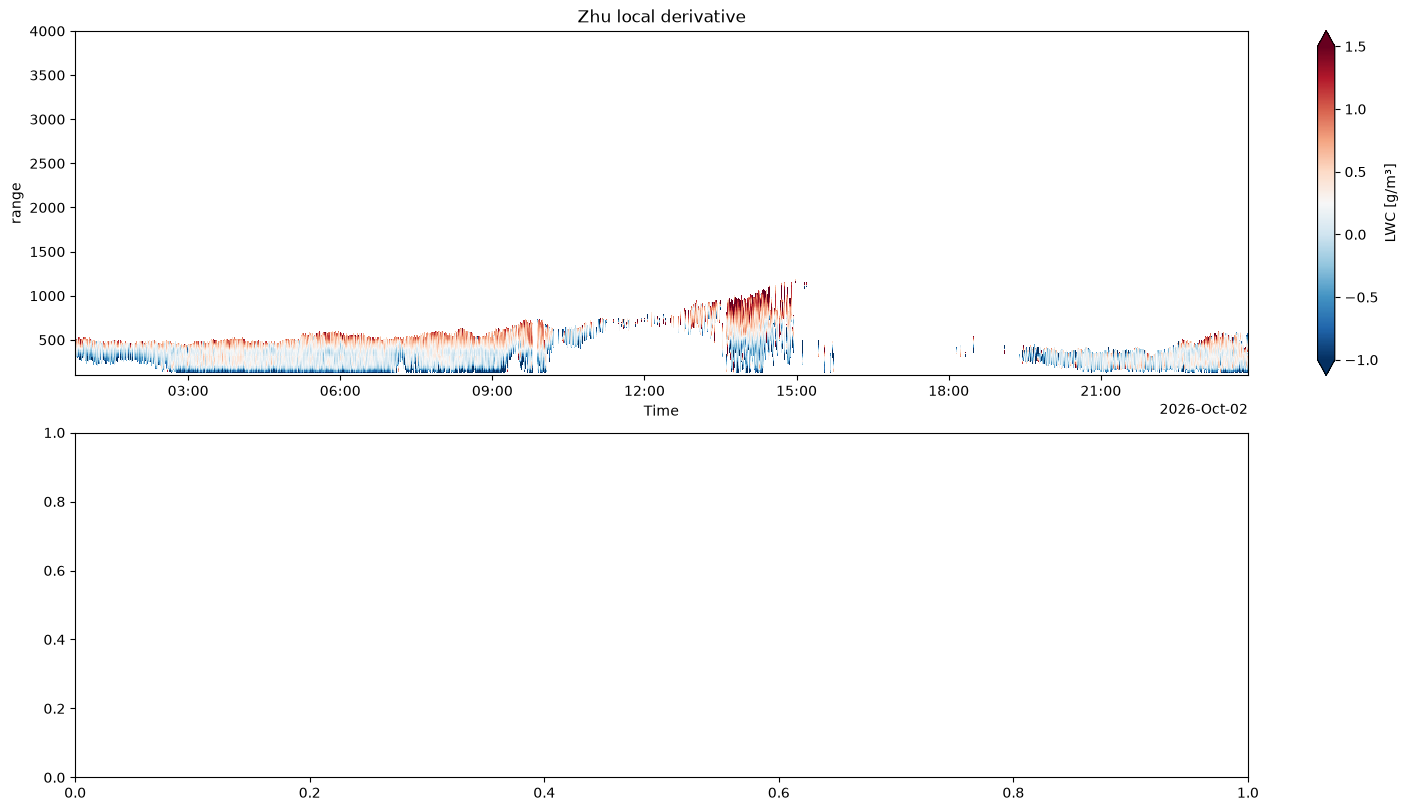

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
lwc_guarded.where(ds_retrieval["common_mask"]).plot(
    x="Time", y="range", ax=axes[0], vmin=-1, vmax=1.5, cmap="RdBu_r",
    cbar_kwargs={"label": "LWC [g/m³]"})
axes[0].set_title("Zhu local derivative")

plt.show()

 ### 4c. Two supporting graphs: LWC distribution + negative-gradient locations

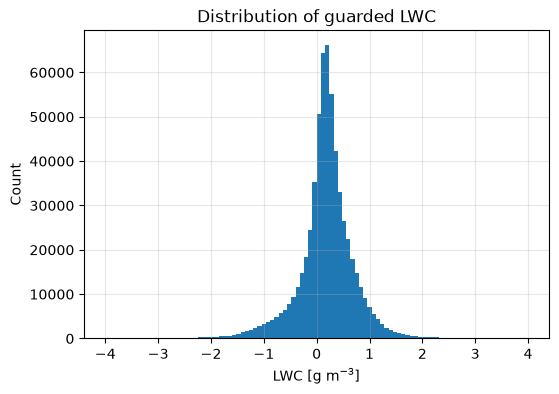

In [20]:
vals = lwc_guarded.where(ds_retrieval["common_mask"]).values
vals = vals[np.isfinite(vals)]

plt.figure(figsize=(6, 4))
plt.hist(vals, bins=100, range=(-4, 4))
plt.xlabel("LWC [g m$^{-3}$]")
plt.ylabel("Count")
plt.title("Distribution of guarded LWC")
plt.grid(alpha=0.3)
plt.show()


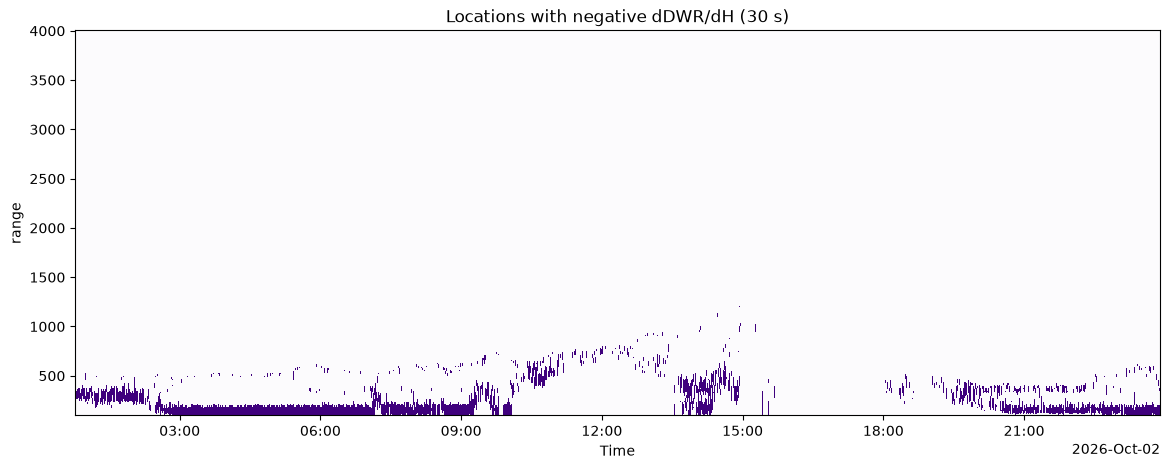

In [21]:
negative_grad = (ddwr_dh_smoothed < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_grad.astype(int).plot(x="Time", y="range", cmap="Purples", add_colorbar=False)
plt.title("Locations with negative dDWR/dH (30 s)")
plt.show()


 ================================================================================================================================================================================================

 ## 5. LWP — kept only for later comparison (general chart, closure scatter, 3-profile spot check)

 ================================================================================================================================================================================================

 ### 5a. General LWP chart

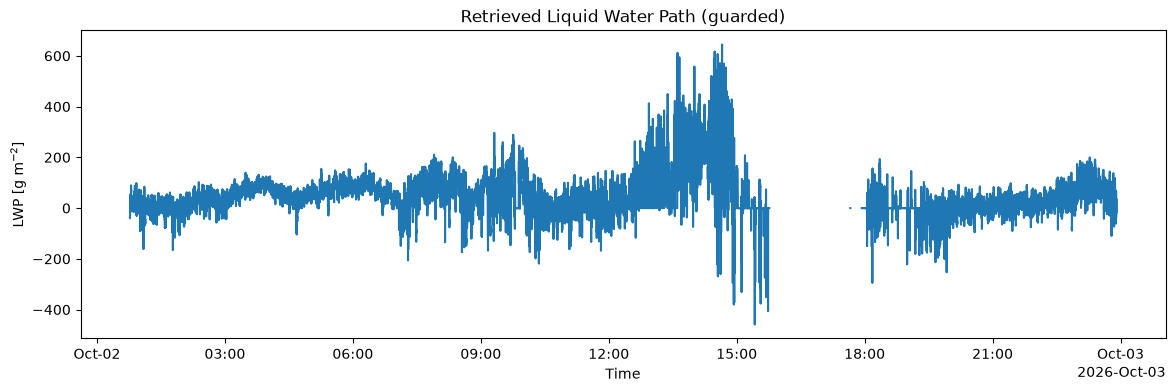

In [22]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_guarded = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded = lwp_guarded.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()


 ### 5b. LWP closure test (scatter vs MWR)

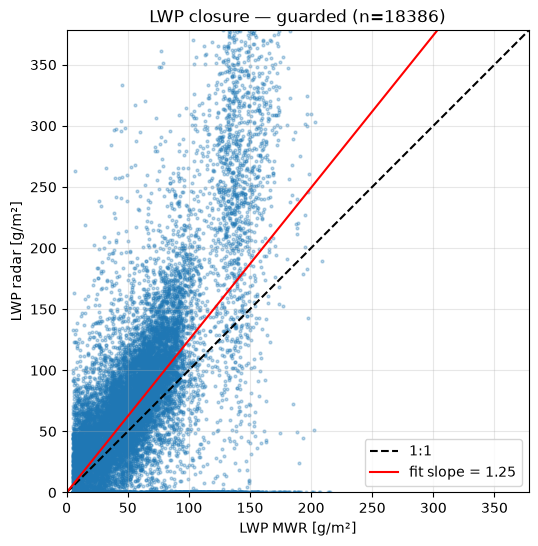

Slope through origin: 1.25   (want ~1.0)
Correlation:          0.59   (want > 0.7)
Bias:  radar - MWR = +12.6 g/m²


In [23]:
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y) & (x > 5)   # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")


 ### 5c. Spot-check three profiles (kept for later comparison across methods)

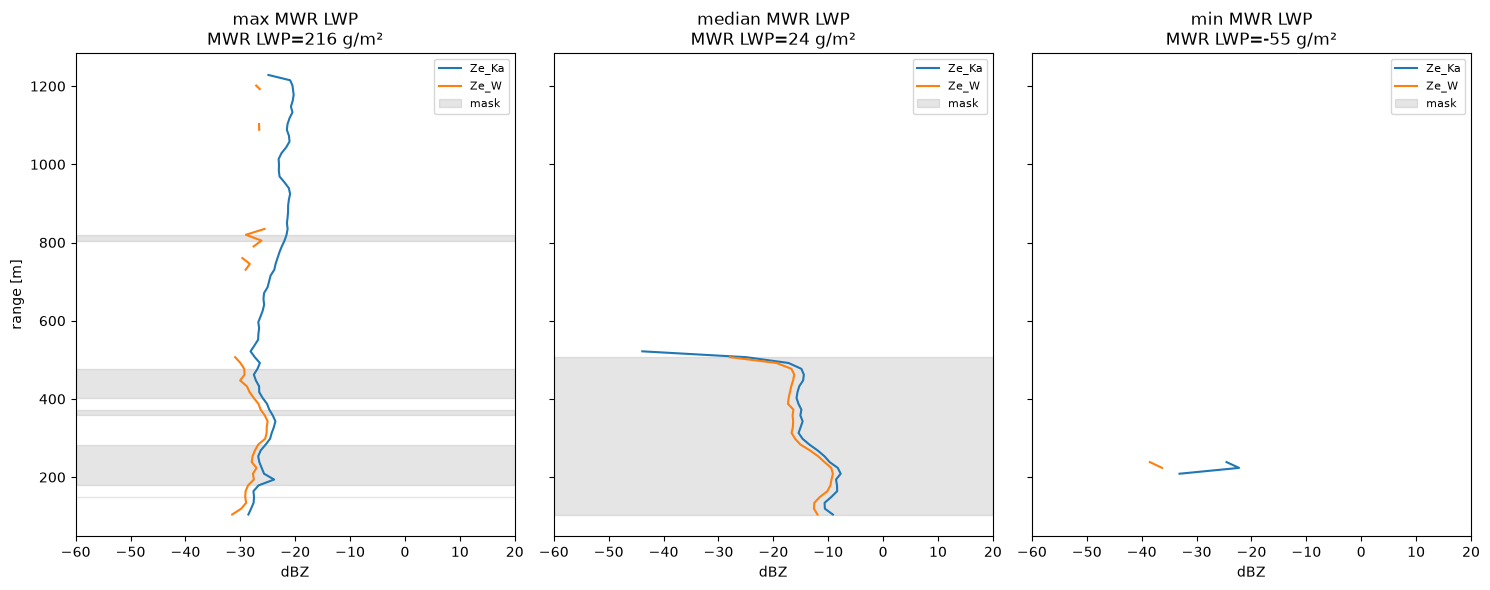

In [24]:
lwp_mwr_vals = ds_retrieval["LWP"].values
i_hi   = int(np.nanargmax(lwp_mwr_vals))
i_lo   = int(np.nanargmin(np.abs(lwp_mwr_vals - np.nanmedian(lwp_mwr_vals))))
i_zero = int(np.nanargmin(lwp_mwr_vals))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, idx, label in zip(axes, [i_hi, i_lo, i_zero],
                          ["max MWR LWP", "median MWR LWP", "min MWR LWP"]):
    h = dwr_2km_smoothed["range"].values
    ax.plot(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)).isel(Time=idx), h, label="Ze_Ka")
    ax.plot(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)).isel(Time=idx),  h, label="Ze_W")
    mask_here = ds_retrieval["common_mask"].isel(Time=idx)
    ax.fill_betweenx(h, -60, 20, where=mask_here, color="grey", alpha=0.2, label="mask")
    ax.set_xlim(-60, 20); ax.set_xlabel("dBZ")
    ax.set_title(f"{label}\nMWR LWP={lwp_mwr_vals[idx]:.0f} g/m²")
    ax.legend(fontsize=8)
axes[0].set_ylabel("range [m]")
plt.tight_layout()
plt.show()


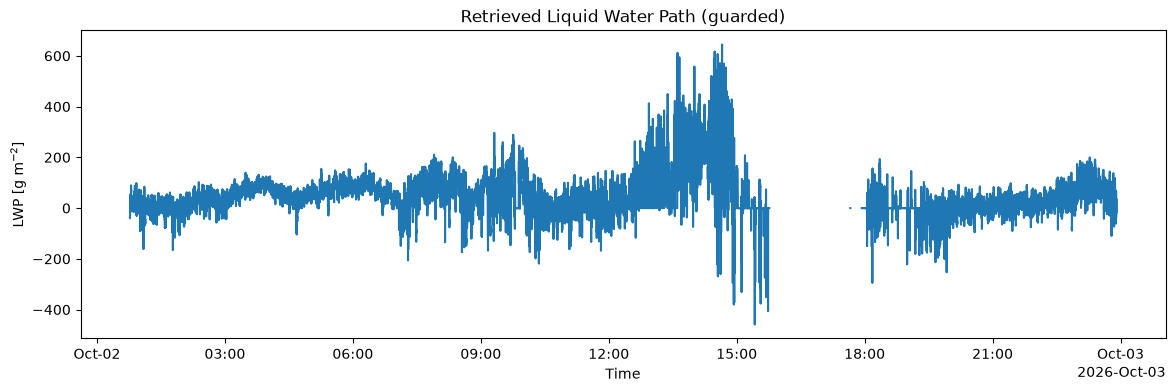

In [25]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})

retrieval_mask = ds_retrieval["common_mask"]

lwp_guarded = (
    lwc_guarded.where(retrieval_mask)
    .fillna(0)
    * dz
).sum(dim="range")

lwp_guarded = lwp_guarded.where(retrieval_mask.any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()

In [26]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_guarded_1500 = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded_1500 = lwp_guarded_1500.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded_1500.attrs["units"] = "g m-2"

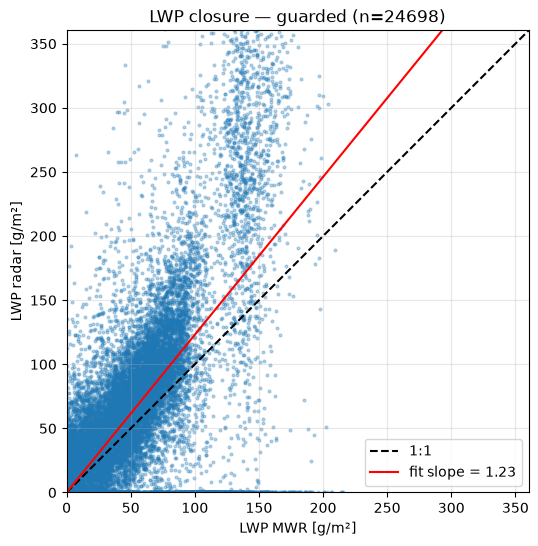

Slope through origin: 1.23   (want ~1.0)
Correlation:          0.64   (want > 0.7)
Bias:  radar - MWR = +12.2 g/m²


In [34]:
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y)    # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")

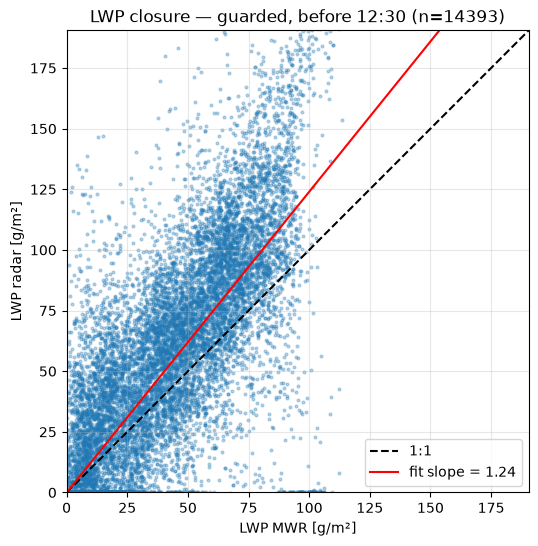

Slope through origin: 1.24   (want ~1.0)
Correlation:          0.70   (want > 0.7)
Bias:  radar - MWR = +7.0 g/m²


In [36]:
t = pd.DatetimeIndex(ds_retrieval["Time"].values)                          # NEW
after = t.time <= pd.Timestamp("12:30").time()                             # NEW

x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = after & np.isfinite(x) & np.isfinite(y)   # ignore near-zero MWR   # NEW: "after &"

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded, before 12:30 (n={good.sum()})")   # NEW: "before 12:30"
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")

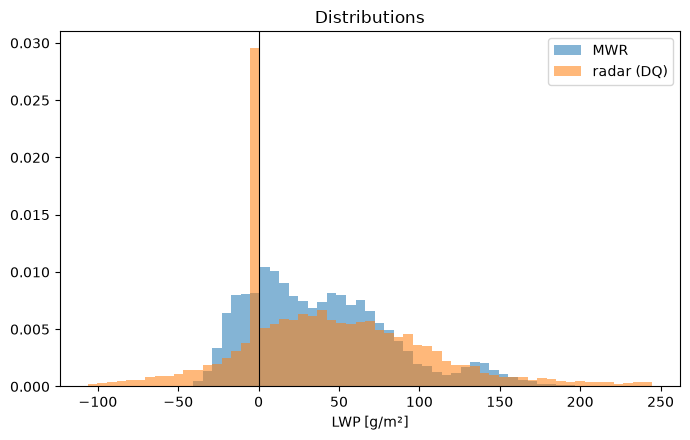

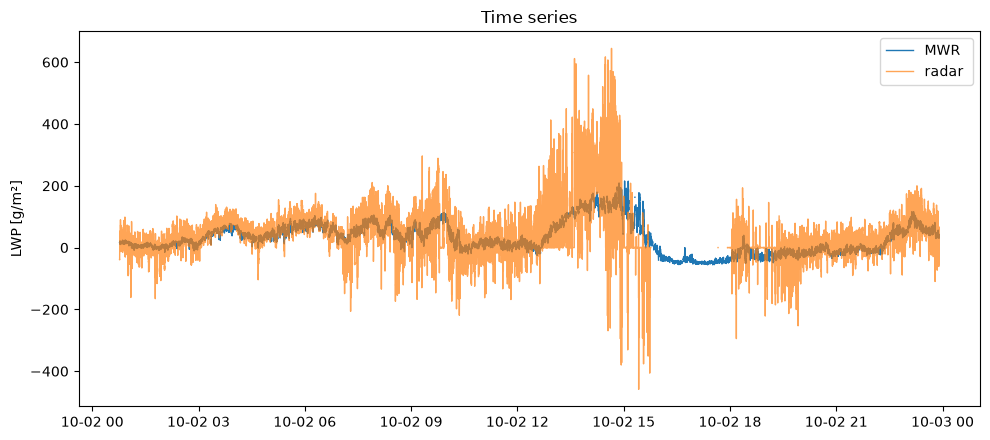

MWR   : mean   +39.8 std   45.4 p05   -19.6 p50   +33.4 p95  +134.9
radar : mean   +52.0 std   82.8 p05   -42.9 p50   +36.7 p95  +214.1


In [38]:
# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) 

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
plt.figure(figsize=(10, 4.5))
plt.plot(ds_retrieval["Time"], x, label="MWR", lw=1)
plt.plot(ds_retrieval["Time"], y, label="radar ", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

2026-10-02T00:00 to 2026-10-02T12:30: 10732 profiles used


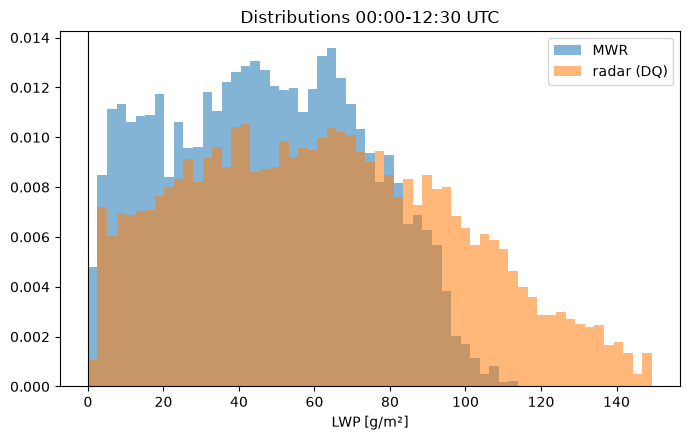

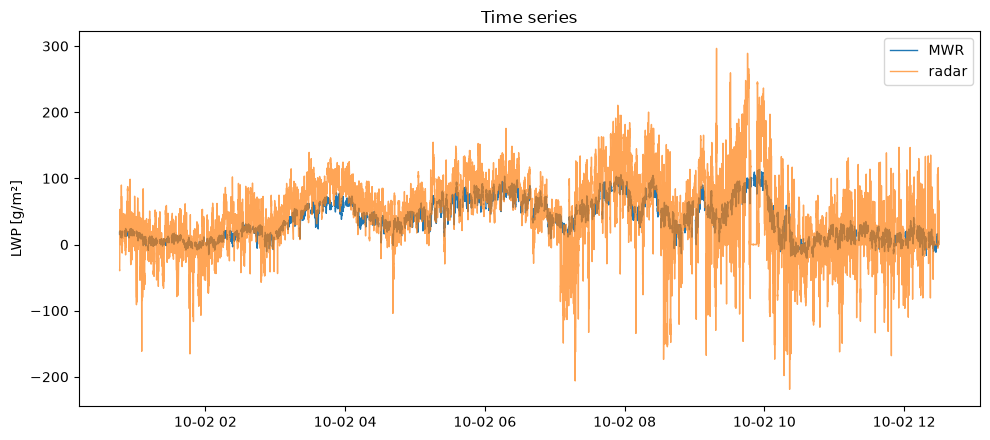

MWR   : mean   +45.9 std   26.7 p05    +4.7 p50   +45.8 p95   +89.5
radar : mean   +67.6 std   42.2 p05    +9.9 p50   +63.2 p95  +141.5


In [37]:
# %% Time window (Cloudnet times are UTC; Finland in October = UTC+3, so 09:00 UTC = 12:00 local)
day = str(ds_retrieval["Time"].values[0])[:10]                  # date of this dataset, e.g. "2026-10-01"
TIME_START = np.datetime64(f"{day}T00:00")
TIME_END   = np.datetime64(f"{day}T12:30")

time = ds_retrieval["Time"].values
in_window = (time >= TIME_START) & (time <= TIME_END)

# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) & (y > 2) & in_window     # <- only the chosen hours
print(f"{TIME_START} to {TIME_END}: {good.sum()} profiles used")

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title(f"Distributions {str(TIME_START)[11:16]}-{str(TIME_END)[11:16]} UTC")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe (only the window)
plt.figure(figsize=(10, 4.5))
plt.plot(time[in_window], x[in_window], label="MWR", lw=1)
plt.plot(time[in_window], y[in_window], label="radar", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

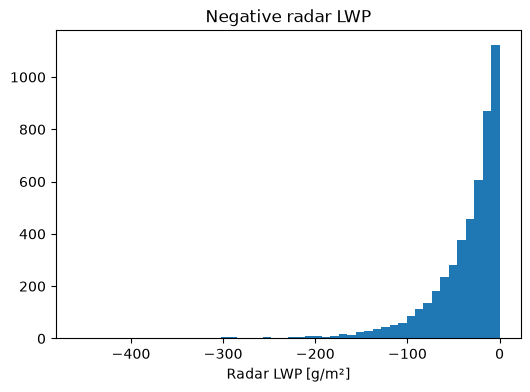

In [30]:
plt.figure(figsize=(6,4))
plt.hist(y[(y < 0) & np.isfinite(y)], bins=50)
plt.xlabel("Radar LWP [g/m²]")
plt.title("Negative radar LWP")
plt.show()

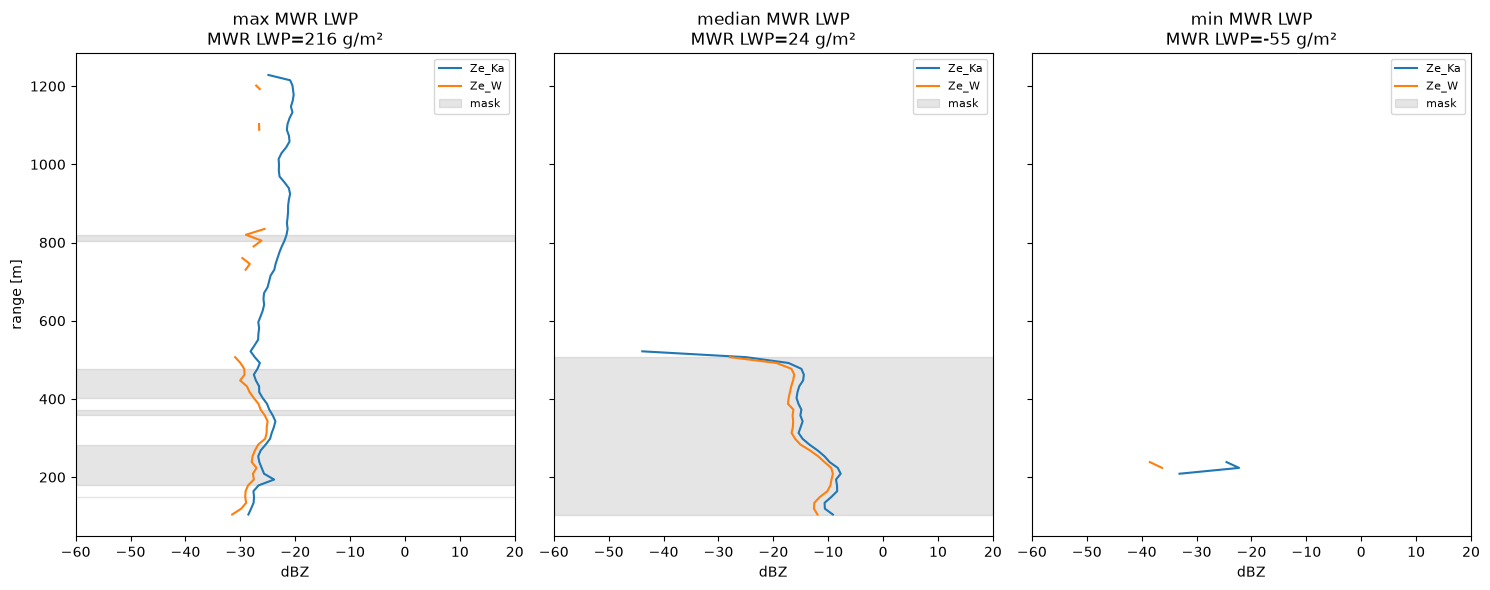

In [31]:
retrieval_mask = ds_retrieval["common_mask"] 

lwp_mwr_vals = ds_retrieval["LWP"].values
i_hi   = int(np.nanargmax(lwp_mwr_vals))
i_lo   = int(np.nanargmin(np.abs(lwp_mwr_vals - np.nanmedian(lwp_mwr_vals))))
i_zero = int(np.nanargmin(lwp_mwr_vals))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

for ax, idx, label in zip(
    axes,
    [i_hi, i_lo, i_zero],
    ["max MWR LWP", "median MWR LWP", "min MWR LWP"],
):
    h = dwr_2km_smoothed["range"].values

    ax.plot(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)).isel(Time=idx), h, label="Ze_Ka")
    ax.plot(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)).isel(Time=idx), h, label="Ze_W")

    mask_here = retrieval_mask.isel(Time=idx)

    ax.fill_betweenx(
        h, -60, 20,
        where=mask_here,
        color="grey",
        alpha=0.2,
        label="mask"
    )

    ax.set_xlim(-60, 20)
    ax.set_xlabel("dBZ")
    ax.set_title(f"{label}\nMWR LWP={lwp_mwr_vals[idx]:.0f} g/m²")
    ax.legend(fontsize=8)

axes[0].set_ylabel("range [m]")
plt.tight_layout()
plt.show()

In [32]:
# %% Export Zhu retrieval outputs for notebook 06
from pathlib import Path
import xarray as xr

ds_output_zhu = xr.Dataset(
    {
        "lwc_guarded":  lwc_guarded.rename("lwc_guarded"),
        "n_windows":    n_windows.rename("n_windows"),
        "dwr_filtered": dwr_2km_filt.rename("dwr_filtered"),
        "m_eff": m_eff.rename("m_eff"),
        "derivative_guarded": derivative_guarded.rename("derivative_guarded"),
        "n_used": n_used.rename("n_used")
        
    },
    attrs={
        "description": "Zhu et al. (2019) guarded retrieval output",
        "N_default": 13,                    # was 9
        "max_ddwr_dh": 30.0,                # add
        "max_window_std": 1.0,              # add
        "edge_pad_bottom": 2,               # add
        "edge_pad_top": 1,                  # add
        "input_dwr": "30 s averaged, 1 dB despiked",
        "mask_used": "common_mask",
        "created_by": "04_zhu_guarded_retrieval_CLEANED.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_output_zhu.to_netcdf(out_path)
print(f"Saved → {out_path}")

Saved → ..\data\processed\20261002_pallas_interpolation_CLARA\retrieval_output_zhu.nc


## Comparison of different number of Gates N

In [39]:
# =====================================================================
# WINDOW-SIZE SWEEP — two rounds: no padding, and (bottom=2, top=1)
# =====================================================================
N_VALUES = [5, 7, 9, 11, 13, 17, 21]
PAD_SETS = [(0, 0), (2, 1)]
MAX_DDWR = 30.0
SIG_DWR_DB = 0.223          # interior per-gate DWR noise

# The window std is signal + noise in quadrature. The signal part grows with
# the window span (so with N), the noise part doesn't. Scale accordingly,
# calibrated so threshold(N=13) = 1.0 dB, i.e. your production value.
K_SIGNAL = np.sqrt(max(1.0**2 - SIG_DWR_DB**2, 0.0)) / 13.0

STD_MODE = "scaled"         # "scaled" | "fixed" (1.0 for all N) | "off"

def std_threshold(N):
    if STD_MODE == "off":   return 1e9
    if STD_MODE == "fixed": return 1.0
    return float(np.sqrt((K_SIGNAL * N) ** 2 + SIG_DWR_DB ** 2))

cmask = ds_retrieval["common_mask"].transpose("Time", "range")
dz    = np.gradient(dwr_2km_filt["range"].values)
dr_m  = float(np.median(np.diff(dwr_2km_filt["range"].values)))
dk    = float((ds_retrieval["kappa_W"] - ds_retrieval["kappa_Ka"])
              .where(cmask).median())

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - restart the kernel"

print(f"gate {dr_m:.1f} m | dkappa {dk:.2f} dB/km/(g/m3) | std mode '{STD_MODE}'")

sweep_N = {}
for pb, pt in PAD_SETS:
    for N in N_VALUES:
        thr = std_threshold(N)
        lwc, *_ = retrieve_lwc_zhu(
            dwr=dwr_2km_filt,
            kappa_w=ds_retrieval["kappa_W"],
            kappa_ka=ds_retrieval["kappa_Ka"],
            alpha_w=ds_retrieval["alpha_W"],
            alpha_ka=ds_retrieval["alpha_Ka"],
            cloud_mask=cmask,
            N_default=N, min_cloud_gates=3,
            max_ddwr_dh=MAX_DDWR, max_window_std=thr,
            edge_pad_bottom=pb, edge_pad_top=pt,
        )
        sweep_N[(pb, pt, N)] = lwc
        print(f"  pad ({pb},{pt})  N={N:>2}  span={N*dr_m:>4.0f} m  "
              f"std_thr={thr:.2f} dB  {int(np.isfinite(lwc.values).sum()):>7} gates")

gate 13.5 m | dkappa 3.61 dB/km/(g/m3) | std mode 'scaled'
  pad (0,0)  N= 5  span=  68 m  std_thr=0.44 dB   682212 gates
  pad (0,0)  N= 7  span=  95 m  std_thr=0.57 dB   686590 gates
  pad (0,0)  N= 9  span= 122 m  std_thr=0.71 dB   686386 gates
  pad (0,0)  N=11  span= 149 m  std_thr=0.85 dB   686725 gates
  pad (0,0)  N=13  span= 176 m  std_thr=1.00 dB   685751 gates
  pad (0,0)  N=17  span= 230 m  std_thr=1.29 dB   674330 gates
  pad (0,0)  N=21  span= 284 m  std_thr=1.59 dB   664853 gates
  pad (2,1)  N= 5  span=  68 m  std_thr=0.44 dB   630446 gates
  pad (2,1)  N= 7  span=  95 m  std_thr=0.57 dB   628710 gates
  pad (2,1)  N= 9  span= 122 m  std_thr=0.71 dB   624396 gates
  pad (2,1)  N=11  span= 149 m  std_thr=0.85 dB   619670 gates
  pad (2,1)  N=13  span= 176 m  std_thr=1.00 dB   615028 gates
  pad (2,1)  N=17  span= 230 m  std_thr=1.29 dB   605662 gates
  pad (2,1)  N=21  span= 284 m  std_thr=1.59 dB   596917 gates


In [40]:
# --- compare ---
lwp_mwr = ds_retrieval["LWP"].values

def sigma_lwc_ols(N, sig_dwr, dr_m, dkappa):
    """OLS slope error through the retrieval equation. White-noise prediction."""
    if N < 3:
        return np.nan
    slope = sig_dwr * np.sqrt(12.0 / (N * (N**2 - 1))) / dr_m * 1000.0   # dB/km
    return 0.5 * slope / dkappa

def diagnose_N(pb, pt):
    print(f"\n=== edge pads (bottom={pb}, top={pt}) ===")
    print(f"{'N':>4}{'span':>6}{'gates':>9}{'prof':>7}{'median':>8}{'std':>7}"
          f"{'pred':>7}{'ratio':>7}{'<0':>6}{'<-1':>7}{'<-2':>7}"
          f" | {'LWPbias%':>9}{'rmse':>7}{'corr':>6}")
    for N in N_VALUES:
        L = sweep_N[(pb, pt, N)].where(cmask).values
        v = L[np.isfinite(L)]
        if v.size < 100:
            print(f"{N:>4}   too few gates ({v.size})")
            continue

        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan
        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)

        if ok.sum() >= 30:
            bias = np.median(100 * (lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
            rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok]) ** 2))
            corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
        else:
            bias = rmse = corr = np.nan

        pred  = sigma_lwc_ols(N, SIG_DWR_DB, dr_m, dk)
        nprof = int(np.isfinite(L).any(axis=1).sum())

        print(f"{N:>4}{N*dr_m:>6.0f}{v.size:>9}{nprof:>7}{np.median(v):>8.3f}"
              f"{v.std():>7.3f}{pred:>7.3f}{v.std()/pred:>7.2f}"
              f"{(v < 0).mean():>6.0%}{(v < -1).mean():>7.1%}{(v < -2).mean():>7.1%}"
              f" | {bias:>9.1f}{rmse:>7.1f}{corr:>6.2f}")

for pb, pt in PAD_SETS:
    diagnose_N(pb, pt)


=== edge pads (bottom=0, top=0) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   682212  28809   0.194  1.046  0.724   1.45   39%  11.3%   4.8% |     -24.8   94.0  0.60
   7    95   686590  28175   0.199  0.973  0.433   2.25   36%  10.5%   4.7% |     -50.8   97.2  0.62
   9   122   686386  27558   0.195  0.914  0.296   3.09   34%   9.9%   4.5% |     -67.6   99.3  0.63
  11   149   686725  27068   0.191  0.891  0.218   4.08   33%   9.7%   4.4% |     -82.2  106.9  0.62
  13   176   685751  26671   0.184  0.856  0.170   5.04   33%   9.5%   4.1% |    -111.5  106.9  0.63
  17   230   674330  25873   0.166  0.716  0.113   6.32   35%   7.8%   2.4% |     -72.0   90.8  0.64
  21   284   664853  25350   0.155  0.648  0.083   7.85   38%   6.5%   0.9% |     -41.1   83.9  0.64

=== edge pads (bottom=2, top=1) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   6304

## Edge Pad analysis

In [41]:
# --- pad sweep ---
PADS      = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2)]
N_DEFAULT = 13
cmask     = ds_retrieval["common_mask"].transpose("Time", "range")

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - a later cell overwrote it; restart the kernel"

sweep_pad = {}
for pb, pt in PADS:
    lwc, *_ = retrieve_lwc_zhu(
        dwr=dwr_2km_filt,
        kappa_w=ds_retrieval["kappa_W"],
        kappa_ka=ds_retrieval["kappa_Ka"],
        alpha_w=ds_retrieval["alpha_W"],
        alpha_ka=ds_retrieval["alpha_Ka"],
        cloud_mask=cmask,
        N_default=N_DEFAULT, min_cloud_gates=3,
        max_ddwr_dh=20.0, max_window_std=1.0,
        edge_pad_bottom=pb, edge_pad_top=pt,
    )
    sweep_pad[(pb, pt)] = lwc
    print(f"  pad ({pb},{pt}): {int(np.isfinite(lwc.values).sum())} gates")


  pad (0,0): 671475 gates
  pad (1,0): 659025 gates
  pad (2,0): 638011 gates
  pad (2,1): 612106 gates
  pad (2,2): 585471 gates


In [42]:

# --- compare ---
dz       = np.gradient(dwr_2km_filt["range"].values)
lwp_mwr  = ds_retrieval["LWP"].values

base     = sweep_pad[PADS[0]].where(cmask).values
base_n   = max(int(np.isfinite(base).sum()), 1)
base_lwp = np.nansum(np.where(np.isfinite(base), base, 0.0) * dz, axis=1)
base_lwp[~np.isfinite(base).any(axis=1)] = np.nan

print(f"{'pad(b,t)':>9}{'gates':>9}{'keep%':>7}{'median':>8}{'std':>7}{'<0':>6}"
      f" | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'vs(0,0)%':>10}")
for k in PADS:
    L = sweep_pad[k].where(cmask).values
    v = L[np.isfinite(L)]
    lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
    lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

    ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
    if v.size == 0 or ok.sum() < 30:
        print(f"{str(k):>9}  too few valid gates/profiles - skipped")
        continue

    bias = np.median(100*(lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
    rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok])**2))
    corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
    ok2  = ok & np.isfinite(base_lwp) & (base_lwp > 0)
    rel  = np.median(100*(lwp_r[ok2] - base_lwp[ok2]) / base_lwp[ok2])

    print(f"{str(k):>9}{v.size:>9}{100*v.size/base_n:>7.1f}{np.median(v):>8.3f}"
          f"{v.std():>7.3f}{(v < 0).mean():>6.0%} | {bias:>9.1f}{rmse:>9.1f}"
          f"{corr:>6.2f}{rel:>10.1f}")

 pad(b,t)    gates  keep%  median    std    <0 |  LWPbias%  LWPrmse  corr  vs(0,0)%
   (0, 0)   671475  100.0   0.181  0.660   32% |     -17.0     80.0  0.66       0.0
   (1, 0)   659025   98.1   0.185  0.636   31% |     -11.6     78.2  0.66       0.0
   (2, 0)   638011   95.0   0.193  0.535   27% |      51.9     79.4  0.65      54.8
   (2, 1)   612106   91.2   0.188  0.513   27% |      38.4     73.1  0.67      35.4
   (2, 2)   585471   87.2   0.178  0.507   28% |      19.6     67.7  0.68      14.4


In [43]:
mask = ds_retrieval["common_mask"].transpose("Time", "range").values.astype(bool)

In [44]:
def sigma_dwr(dwr_block, mask_block):
    """sigma_DWR from adjacent-gate differences, per-profile trend removed."""
    x = np.asarray(dwr_block, float).copy()
    x[~np.asarray(mask_block, bool)] = np.nan
    k = np.arange(x.shape[1], dtype=float)
    for t in range(x.shape[0]):
        g = np.isfinite(x[t])
        if g.sum() >= 3:
            x[t, g] -= np.polyval(np.polyfit(k[g], x[t, g], 1), k[g])
    d = np.diff(x, axis=1).ravel()
    d = d[np.isfinite(d)]
    return (np.sqrt(np.var(d, ddof=1)/2), d.size) if d.size > 30 else (np.nan, 0)


# mean cloud height per profile
r = ds_retrieval["range"].values
h_mid = np.array([r[np.flatnonzero(m)].max() if m.sum() >= 3 else np.nan
                  for m in mask])

edges = np.nanpercentile(h_mid, [0, 20, 40, 60, 80, 100])
centres, sigmas = [], []
for i in range(len(edges)-1):
    sel = (h_mid >= edges[i]) & (h_mid < edges[i+1])
    if sel.sum() < 30:
        continue
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    centres.append(np.nanmean(h_mid[sel])); sigmas.append(s)
    print(f"  h ~ {centres[-1]:6.0f} m : sigma {s:.3f} dB "
          f"({sel.sum()} profiles, {n} pairs)")

centres, sigmas = np.array(centres), np.array(sigmas)
if len(centres) >= 3:
    a, b = np.polyfit(1/centres, sigmas, 1)
    print(f"\nfit sigma = a/h + b  ->  a = {a:.0f} dB*m, b = {b:.3f} dB")
    print(f"predicted sigma at 750 m: {a/750+b:.3f}, "
          f"at 1400 m: {a/1400+b:.3f} dB")

  h ~    392 m : sigma 0.224 dB (5730 profiles, 83652 pairs)
  h ~    483 m : sigma 0.234 dB (5071 profiles, 107278 pairs)
  h ~    533 m : sigma 0.267 dB (6793 profiles, 179602 pairs)
  h ~    626 m : sigma 0.316 dB (6320 profiles, 171467 pairs)
  h ~    916 m : sigma 0.287 dB (6291 profiles, 165500 pairs)

fit sigma = a/h + b  ->  a = -55 dB*m, b = 0.366 dB
predicted sigma at 750 m: 0.293, at 1400 m: 0.327 dB


In [45]:
def sigma_dwr(dwr_block, mask_block):
    """sigma_DWR from adjacent-gate differences, per-profile trend removed."""
    x = np.asarray(dwr_block, float).copy()
    x[~np.asarray(mask_block, bool)] = np.nan
    k = np.arange(x.shape[1], dtype=float)
    for t in range(x.shape[0]):
        g = np.isfinite(x[t])
        if g.sum() >= 3:
            x[t, g] -= np.polyval(np.polyfit(k[g], x[t, g], 1), k[g])
    d = np.diff(x, axis=1).ravel()
    d = d[np.isfinite(d)]
    return (np.sqrt(np.var(d, ddof=1)/2), d.size) if d.size > 30 else (np.nan, 0)

height_mask = (r >= 1) & (r <= 10000)
dwr_2km_filt = dwr_2km_filt[:, height_mask]
mask = mask[:, height_mask]
r = r[height_mask]

# mean cloud height per profile
r = ds_retrieval["range"].values
h_mid = np.array([r[np.flatnonzero(m)].mean() if m.sum() >= 3 else np.nan
                  for m in mask])

edges = np.nanpercentile(h_mid, [0, 20, 40, 60, 80, 100])
centres, sigmas = [], []
for i in range(len(edges)-1):
    sel = (h_mid >= edges[i]) & (h_mid < edges[i+1])
    if sel.sum() < 30:
        continue
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    centres.append(np.nanmean(h_mid[sel])); sigmas.append(s)
    print(f"  h ~ {centres[-1]:6.0f} m : sigma {s:.3f} dB "
          f"({sel.sum()} profiles, {n} pairs)")

centres, sigmas = np.array(centres), np.array(sigmas)
if len(centres) >= 3:
    a, b = np.polyfit(1/centres, sigmas, 1)
    print(f"\nfit sigma = a/h + b  ->  a = {a:.0f} dB*m, b = {b:.3f} dB")
    print(f"predicted sigma at 750 m: {a/750+b:.3f}, "
          f"at 1400 m: {a/1400+b:.3f} dB")

  h ~    267 m : sigma 0.244 dB (5497 profiles, 98126 pairs)
  h ~    310 m : sigma 0.227 dB (5880 profiles, 147308 pairs)
  h ~    342 m : sigma 0.280 dB (6464 profiles, 175057 pairs)
  h ~    425 m : sigma 0.333 dB (6327 profiles, 158264 pairs)
  h ~    699 m : sigma 0.262 dB (6042 profiles, 128853 pairs)

fit sigma = a/h + b  ->  a = -19 dB*m, b = 0.321 dB
predicted sigma at 750 m: 0.296, at 1400 m: 0.308 dB


In [46]:
# DWR residual after removing a smooth per-profile fit = what the retrieval calls noise
resid = np.full_like(dwr_2km_filt, np.nan)
kk = np.arange(dwr_2km_filt.shape[1], dtype=float)
for t in range(dwr_2km_filt.shape[0]):
    g = mask[t] & np.isfinite(dwr_2km_filt[t])
    if g.sum() >= 4:
        resid[t, g] = dwr_2km_filt[t, g] - np.polyval(np.polyfit(kk[g], dwr_2km_filt[t, g], 2), kk[g])

# local temporal Ze variability = proxy for small-scale spatial variability
ze = np.where(mask, ds_retrieval["Ze_W"], np.nan)
W = 5   # profiles, ~ a few seconds
loc_var = np.full_like(ze, np.nan)
for t in range(W, ze.shape[0] - W):
    loc_var[t] = np.nanstd(ze[t-W:t+W+1], axis=0)

a, b = np.abs(resid).ravel(), loc_var.ravel()
g = np.isfinite(a) & np.isfinite(b)
print(f"corr(|DWR residual|, local Ze variability) = "
      f"{np.corrcoef(a[g], b[g])[0,1]:+.3f}   (n={g.sum()})")

c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


corr(|DWR residual|, local Ze variability) = +0.087   (n=749767)


In [47]:
import xarray as xr
import glob
Dataset_94GHz = "20230930_94GHz"
def load_rpg(folder):
     files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))
     ds = xr.open_mfdataset(files, combine="by_coords")    # Combine="by_coords" orders them immediately by coordinates, in this case by the time so it is immediately in structure 7:01...7:02...7:03
     epoch = pd.Timestamp("2001-01-01")
     ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
     ds = drop_duplicate_times(ds)
     return ds

raw  = load_rpg(f"../data/raw/cmtrace/{Dataset_94GHz}")

C:\Users\geron\AppData\Local\Temp\ipykernel_20952\2248784253.py:6: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(files, combine="by_coords")    # Combine="by_coords" orders them immediately by coordinates, in this case by the time so it is immediately in structure 7:01...7:02...7:03


In [48]:
print(raw["SurfWS"])

<xarray.DataArray 'SurfWS' (Time: 14915)> Size: 60kB
dask.array<getitem, shape=(14915,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[us] 119kB 2023-09-30T20:02:27 ... 2023-10-01T0...
Attributes:
    Name:     Surface wind speed from weather station
    Units:    m/s


In [49]:
wind_speed = raw["SurfWS"].values

In [50]:
# advection speed proxy: horizontal wind from sounding, or the Doppler
# spectrum-width / mean-velocity variability. Bin sigma_DWR by it.
for lo, hi in [(0,3), (3,6), (6,10), (10,20)]:
    sel = mask & (wind_speed[:,None] >= lo) & (wind_speed[:,None] < hi)
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    print(f"U {lo:2d}-{hi:2d} m/s : sigma {s:.3f} dB  (n={n})")

ValueError: operands could not be broadcast together with shapes (35268,237) (14915,1) 

In [ ]:
d = np.diff(np.where(mask, dwr_2km_filt, np.nan), axis=1)

edge, interior = [], []
for t in range(mask.shape[0]):
    idx = np.flatnonzero(mask[t])
    if idx.size < 6:
        continue
    lo, hi = idx[0], idx[-1]
    for k in range(lo, hi):                      # k indexes the pair (k, k+1)
        if not np.isfinite(d[t, k]):
            continue
        (edge if (k == lo or k == hi - 1) else interior).append(d[t, k])

e, i = np.array(edge), np.array(interior)
f = e.std() / i.std()
print(f"edge pairs     n={e.size:6d}  std(delta)={e.std():.3f}")
print(f"interior pairs n={i.size:6d}  std(delta)={i.std():.3f}")
print(f"f = {f:.2f}   ->  {'DROP the edge gates' if f > 1.8 else 'KEEP them'}")

ValueError: operands could not be broadcast together with shapes (14915,45) (14915,127) () 